# Direction 1 — Direct Ordinal-Geometry Text Embeddings
## DeepDRiD Benchmark — Training, Baselines, Ablations & Figures

Companion to `DeepDRiD_FewShot_DR_fixed.ipynb` for the `direction1-ordinal-geometry` branch.
Instead of learning prompt tokens, Direction 1 learns the five grade embeddings directly in
CLIP's joint space, starting from clinical text, and shapes them with three geometry losses
(ladder, path, anchor). See `docs/superpowers/specs/` for the design.

Every run is a config file under `configs/` plus `data.k_shot` / `data.seed`, trained in-process
with the same rules as `scripts/train.py`. Finished runs are cached in `results_d1/`.

| Section | What it does |
|---|---|
| 1–3 | setup, experiment grid, data check |
| 4 | single-run helper |
| 5 | main comparison: Direction 1 vs. matched baselines |
| 6 | Direction 1 ablations |
| 7 | mean ± std tables |
| 8 | figures: k-shot curves, ablation bars, confusion matrices, error decay, embedding geometry |

## 1 · Environment Setup

In [1]:
import os, sys, io, json, warnings, logging, contextlib
from pathlib import Path

import numpy as np
import pandas as pd
import torch
import pytorch_lightning as pl
import matplotlib.pyplot as plt
import matplotlib.ticker as mticker
from pytorch_lightning.callbacks import EarlyStopping, ModelCheckpoint
from tqdm.auto import tqdm   # widget bars in Jupyter, text bars in a terminal

warnings.filterwarnings('ignore')
for _name in ('pytorch_lightning', 'lightning', 'lightning.pytorch', 'lightning_fabric'):
    logging.getLogger(_name).setLevel(logging.ERROR)

# ── Locate project root (contains 'configs/' dir) ────────────────────────────
ROOT = Path.cwd()
while not (ROOT / 'configs').exists():
    ROOT = ROOT.parent
os.chdir(ROOT)
sys.path.insert(0, str(ROOT))

from scripts.train import load_config, select_precision, restore_best_weights, json_safe
from src.data.datamodule import FewShotDataModule
from src.models.runner import FewShotOrdinalRunner

# ── Data folder ──────────────────────────────────────────────────────────────
# data/ is not in git. A worktree has none, so look in the project root and its
# parents (the main checkout), or set DATA_DIR yourself.
DATA_DIR = None
if DATA_DIR is None:
    for base in [ROOT, *ROOT.parents]:
        if (base / 'data/DeepDRiD/CFP_manifest.csv').exists():
            DATA_DIR = base / 'data/DeepDRiD'
            break
assert DATA_DIR is not None, 'DeepDRiD manifest not found: run scripts/prepare_external_datasets.py and src/data/build_splits.py in the main checkout, or set DATA_DIR.'
MANIFEST, SPLITS_DIR = DATA_DIR / 'CFP_manifest.csv', DATA_DIR / 'splits'

RESULTS = ROOT / 'results_d1'
FIGURES = RESULTS / 'figures'
FIGURES.mkdir(parents=True, exist_ok=True)

DEVICE = 'cuda' if torch.cuda.is_available() else 'cpu'
print(f'Project root : {ROOT}')
print(f'Data         : {DATA_DIR}')
print(f'Results dir  : {RESULTS}')
print(f'Device       : {DEVICE} | PyTorch {torch.__version__} | PL {pl.__version__}')

Project root : e:\Research\Dr.Mohammad(LAB)\ordinal classify\MMRDR\Workspace\.claude\worktrees\direction1
Data         : e:\Research\Dr.Mohammad(LAB)\ordinal classify\MMRDR\Workspace\data\DeepDRiD
Results dir  : e:\Research\Dr.Mohammad(LAB)\ordinal classify\MMRDR\Workspace\.claude\worktrees\direction1\results_d1
Device       : cuda | PyTorch 2.8.0+cu126 | PL 2.6.5


## 2 · Experiment Grid

Each entry maps a name to a config file. `own_budget=True` keeps the config's own epochs and
schedule (the official OrdinalCLIP recipe and native CLAP); every other run uses `EPOCHS`,
the same budget as the main notebook.

In [2]:
K_SHOTS = [-1, 0, 1, 2, 4, 8, 16, 32]   # -1 = full data, 0 = zero-shot (no training)
SEEDS   = [1, 2, 3]
EPOCHS  = 50

# Main comparison: Direction 1 against matched baselines (same backbone, budget, data)
METHODS = {
    'Direction 1':            {'config': 'configs/direction1/d1_full.yaml'},
    'RankFormer (ours)':      {'config': 'configs/direction1/d1_rankformer.yaml'},
    'OrdinalCLIP (matched)':  {'config': 'configs/baselines/ordinalclip_matched.yaml'},
    'CLIP-DR (matched)':      {'config': 'configs/baselines/clipdr_matched.yaml'},
    'L2RCLIP (matched)':      {'config': 'configs/baselines/l2rclip_matched.yaml'},
    'CLAP (matched)':         {'config': 'configs/baselines/clap_matched.yaml'},
    'OrdinalCLIP (official)': {'config': 'configs/baselines/ordinalclip_official.yaml', 'own_budget': True},
    'CLAP (native)':          {'config': 'configs/baselines/clap_native.yaml', 'own_budget': True},
}

# Direction 1 ablations (each differs from d1_full in one thing)
ABLATIONS = {
    'Direction 1':                {'config': 'configs/direction1/d1_full.yaml'},
    'w/o ladder':                 {'config': 'configs/direction1/d1_no_ladder.yaml'},
    'w/o path':                   {'config': 'configs/direction1/d1_no_path.yaml'},
    'w/o anchor':                 {'config': 'configs/direction1/d1_no_anchor.yaml'},
    'w/o geometry losses':        {'config': 'configs/direction1/d1_no_geometry.yaml'},
    'CE + geometry only':         {'config': 'configs/direction1/d1_ce_geometry.yaml'},
    'init: plain prompts':        {'config': 'configs/direction1/d1_init_plain.yaml'},
    'init: random orthogonal':    {'config': 'configs/direction1/d1_init_random.yaml'},
    'anchor: inverse-sqrt freq.': {'config': 'configs/direction1/d1_anchor_invsqrt.yaml'},
}
ABLATION_K_SHOTS = [-1, 1, 4, 8, 16, 32]

n_main = len(METHODS) * len(K_SHOTS) * len(SEEDS)
n_abl = (len(ABLATIONS) - 1) * len(ABLATION_K_SHOTS) * len(SEEDS)
print(f'Main comparison: {n_main} runs | ablations: {n_abl} extra runs (Direction 1 runs are shared)')

Main comparison: 192 runs | ablations: 144 extra runs (Direction 1 runs are shared)


## 3 · Data Check

The manifest uses per-eye grades; every k-shot split must exist before training.

1,600 images | train: 1,200, test: 400
All split files present.


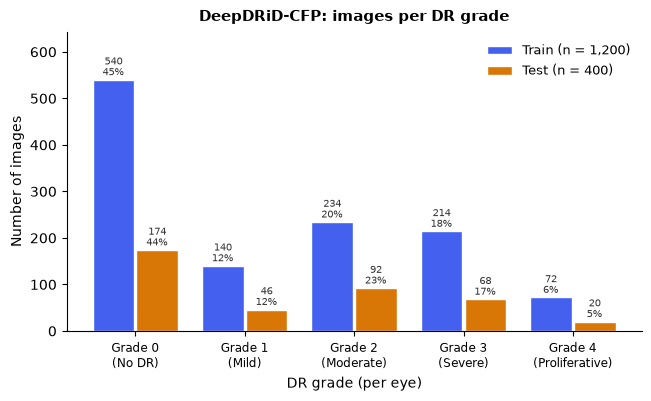

In [3]:
manifest = pd.read_csv(MANIFEST)
print(f'{len(manifest):,} images | ' + ', '.join(f"{s}: {n:,}" for s, n in manifest['split'].value_counts().items()))
missing = [(k, s) for k in K_SHOTS if k > 0 for s in SEEDS
           if not (SPLITS_DIR / f'cfp_{k}shot_s{s}_support.txt').exists()]
assert not missing, f'Missing split files for (k, seed) = {missing}: run src/data/build_splits.py'
print('All split files present.')

plt.rcParams.update({'font.family': 'DejaVu Sans', 'axes.spines.top': False,
                     'axes.spines.right': False, 'axes.grid': False})
GRADE_NAMES = ['Grade 0\n(No DR)', 'Grade 1\n(Mild)', 'Grade 2\n(Moderate)',
               'Grade 3\n(Severe)', 'Grade 4\n(Proliferative)']
fig, ax = plt.subplots(figsize=(6.4, 3.9), constrained_layout=True)
grades = np.arange(5)
for i, (split, label, color) in enumerate([('train', 'Train', '#4361EE'), ('test', 'Test', '#D97706')]):
    counts = manifest[manifest['split'] == split]['grade'].value_counts().reindex(grades, fill_value=0)
    bars = ax.bar(grades + (i - 0.5) * 0.40, counts.values, width=0.38, color=color, edgecolor='white',
                  label=f'{label} (n = {counts.sum():,})')
    for bar, n in zip(bars, counts.values):
        ax.text(bar.get_x() + bar.get_width() / 2, n + 6, f'{n:,}\n{n / counts.sum() * 100:.0f}%',
                ha='center', va='bottom', fontsize=7, color='#333333', linespacing=1.1)
ax.set_title('DeepDRiD-CFP: images per DR grade', fontsize=11, fontweight='bold', pad=8)
ax.set_xticks(grades); ax.set_xticklabels(GRADE_NAMES, fontsize=8.5)
ax.set_xlabel('DR grade (per eye)'); ax.set_ylabel('Number of images')
ax.set_ylim(0, manifest['grade'].value_counts().max() * 0.9)
ax.legend(frameon=False, fontsize=9)
plt.show()

## 4 · Single-Run Helper

Same flow as the main notebook: validation every epoch, `best.ckpt` (best `val_qwk`) and
`last.ckpt` written after every epoch, an interrupted run resumes from `last.ckpt`, and the
test uses the best checkpoint. k = 0 tests the untrained model. Finished runs are cached.

Progress: the outer bar counts runs; the inner bar follows one run (one k and seed) epoch by
epoch with its loss, validation QWK and best validation QWK. Lightning's own bar and per-run
prints are switched off so both bars update in place.

In [4]:
class EpochBar(pl.Callback):
    # Plain tqdm bars for one run: one tick per epoch (loss / val QWK / best val QWK),
    # and below it one tick per batch of the current epoch (training, then validation)

    def __init__(self, desc: str, total: int):
        self.desc, self.total, self.bar, self.best = desc, total, None, None
        self.batch_bar = None

    def on_train_epoch_start(self, trainer, pl_module):
        n_train = trainer.num_training_batches
        n_val = sum(trainer.num_val_batches) if trainer.num_val_batches else 0
        self.batch_bar = tqdm(total=n_train + n_val, desc=f'  epoch {trainer.current_epoch + 1}',
                              leave=False, unit='batch', dynamic_ncols=True)

    def on_train_batch_end(self, trainer, pl_module, outputs, batch, batch_idx):
        if self.batch_bar is not None:
            self.batch_bar.set_postfix_str('train', refresh=False)
            self.batch_bar.update(1)

    def on_validation_batch_end(self, trainer, pl_module, outputs, batch, batch_idx, dataloader_idx=0):
        # Skip Lightning's sanity check, which runs before the first epoch
        if self.batch_bar is not None and not trainer.sanity_checking:
            self.batch_bar.set_postfix_str('val', refresh=False)
            self.batch_bar.update(1)

    def on_train_start(self, trainer, pl_module):
        # A resumed run starts from the checkpoint's epoch and best score
        score = trainer.checkpoint_callback.best_model_score if trainer.checkpoint_callback else None
        self.best = float(score) if score is not None else None
        self.bar = tqdm(total=self.total, initial=trainer.current_epoch, desc=self.desc,
                        leave=False, unit='epoch', dynamic_ncols=True)

    def on_train_epoch_end(self, trainer, pl_module):
        # Lightning runs ModelCheckpoint after other callbacks, so track the best here
        m = trainer.callback_metrics
        post = {key: f'{float(m[src]):.3f}' for key, src in (('loss', 'train_loss'), ('val_qwk', 'val_qwk')) if src in m}
        if 'val_qwk' in m:
            self.best = max(self.best if self.best is not None else -1.0, float(m['val_qwk']))
        if self.best is not None:
            post['best'] = f'{self.best:.3f}'
        self.bar.set_postfix(post, refresh=False)
        self.bar.update(1)
        if self.batch_bar is not None:
            self.batch_bar.close()
            self.batch_bar = None

    def on_train_end(self, trainer, pl_module):
        for bar in (self.batch_bar, self.bar):
            if bar is not None:
                bar.close()


def run_experiment(name: str, spec: dict, k_shot: int, seed: int, force_retrain: bool = False) -> dict:
    slug = name.replace(' ', '_').replace('/', '_').replace('(', '').replace(')', '').replace(':', '').replace('.', '')
    out_dir = RESULTS / slug / f'CFP_{k_shot}shot_s{seed}'
    stats_file = out_dir / 'test_stats.json'
    if stats_file.exists() and not force_retrain:
        return json.load(open(stats_file))
    out_dir.mkdir(parents=True, exist_ok=True)

    overrides = [f'data.k_shot={k_shot}', f'data.seed={seed}',
                 f'data.manifest={MANIFEST.as_posix()}', f'data.splits_dir={SPLITS_DIR.as_posix()}']
    if not spec.get('own_budget', False):
        overrides.append(f'train.epochs={EPOCHS}')
    overrides += [f'{k}={v}' for k, v in spec.get('extra', {}).items()]
    cfg = load_config(spec['config'], overrides)

    # Per-run prints (seed, parameter count, anchor weights) would break the progress bars
    with contextlib.redirect_stdout(io.StringIO()):
        pl.seed_everything(seed, workers=True, verbose=False)
        datamodule = FewShotDataModule(cfg)
        model = FewShotOrdinalRunner(cfg)

    monitor = cfg.train.get('early_stopping_monitor', 'val_qwk')
    mode = cfg.train.get('early_stopping_mode', 'max')
    checkpoint = ModelCheckpoint(dirpath=str(out_dir), filename='best', monitor=monitor, mode=mode,
                                 save_top_k=1, save_last=True)
    callbacks = [EarlyStopping(monitor=monitor, patience=cfg.train.get('early_stopping_patience', 20), mode=mode),
                 checkpoint,
                 EpochBar(f'{name} | k={k_shot} seed={seed}', cfg.train.epochs)]
    trainer = pl.Trainer(
        max_epochs=cfg.train.epochs if k_shot != 0 else 0,
        accelerator='auto', devices=1,
        precision=select_precision(cfg.train, torch.cuda.is_available() and torch.cuda.is_bf16_supported()),
        gradient_clip_val=1.0,
        callbacks=callbacks,
        log_every_n_steps=1, enable_checkpointing=True, logger=False,
        enable_progress_bar=False, enable_model_summary=False,
    )

    geometry = []
    with contextlib.redirect_stdout(io.StringIO()):
        if k_shot != 0:
            last_ckpt = out_dir / 'last.ckpt'
            trainer.fit(model, datamodule=datamodule,
                        ckpt_path=str(last_ckpt) if last_ckpt.exists() else None, weights_only=False)
            geometry = list(model.geometry_history)
            # Test with the best checkpoint
            if checkpoint.best_model_path:
                restore_best_weights(model, checkpoint.best_model_path)
        trainer.test(model, datamodule=datamodule, verbose=False)

    metrics = json_safe(model.latest_metrics)
    json.dump(metrics, open(stats_file, 'w'), indent=4)
    if geometry:
        json.dump(json_safe(geometry), open(out_dir / 'geometry.json', 'w'), indent=2)
    return metrics


def run_grid(variants: dict, k_shots: list[int], seeds: list[int], desc: str) -> pd.DataFrame:
    rows = []
    pbar = tqdm(total=len(variants) * len(k_shots) * len(seeds), desc=desc, unit='run', dynamic_ncols=True)
    for k in k_shots:
        for name, spec in variants.items():
            for seed in seeds:
                pbar.set_postfix({'variant': name, 'k': k, 'seed': seed})
                rows.append({'Variant': name, 'k': k, 'Seed': seed, **run_experiment(name, spec, k, seed)})
                pbar.update(1)
    pbar.close()
    return pd.DataFrame(rows)

print('run_experiment() and run_grid() defined.')

run_experiment() and run_grid() defined.


## 5 · Main Comparison

In [ ]:
RUN_MAIN = True
df_main = run_grid(METHODS, K_SHOTS, SEEDS, 'Main') if RUN_MAIN else pd.DataFrame()
print('Main results:', df_main.shape)

Main:   0%|          | 0/192 [00:00<?, ?run/s]

Direction 1 | k=-1 seed=1:   2%|2         | 1/50 [00:00<?, ?epoch/s]

  epoch 2:   0%|          | 0/38 [00:00<?, ?batch/s]

  epoch 3:   0%|          | 0/38 [00:00<?, ?batch/s]

## 6 · Direction 1 Ablations

In [ ]:
RUN_ABLATIONS = True
df_abl = run_grid(ABLATIONS, ABLATION_K_SHOTS, SEEDS, 'Ablations') if RUN_ABLATIONS else pd.DataFrame()
print('Ablation results:', df_abl.shape)

## 7 · Results Tables (mean ± std over seeds)

In [ ]:
METRICS = ['qwk', 'mae', 'f1', 'auc', 'acc', 'odc_full', 'odc_offdiag', 'ece']
METRIC_LABELS = {'qwk': 'QWK ↑', 'mae': 'MAE ↓', 'f1': 'Macro-F1 ↑', 'auc': 'AUC ↑', 'acc': 'Accuracy ↑',
                 'odc_full': 'ODC (full) ↑', 'odc_offdiag': 'ODC (off-diag.) ↑', 'ece': 'ECE ↓'}

def aggregate(df: pd.DataFrame, group_cols: list[str]) -> pd.DataFrame:
    rows = []
    for keys, grp in df.groupby(group_cols, sort=False):
        row = dict(zip(group_cols, keys if isinstance(keys, tuple) else [keys]))
        for m in METRICS:
            if m in grp.columns:
                row[f'{m}_mean'] = grp[m].mean()
                row[f'{m}_std'] = grp[m].std(ddof=1) if len(grp) > 1 else 0.0
                row[m] = f"{row[f'{m}_mean']:.3f} ± {row[f'{m}_std']:.3f}"
        rows.append(row)
    return pd.DataFrame(rows)

def k_label(k):
    return {-1: 'full', 0: 'zero-shot'}.get(k, f'{k}-shot')

if not df_main.empty:
    agg_main = aggregate(df_main, ['Variant', 'k'])
    agg_main.to_csv(RESULTS / 'main_results.csv', index=False)
    qwk_table = agg_main.pivot(index='Variant', columns='k', values='qwk').reindex(list(METHODS))
    qwk_table.columns = [k_label(k) for k in qwk_table.columns]
    print('QWK — main comparison'); display(qwk_table)

if not df_abl.empty:
    agg_abl = aggregate(df_abl, ['Variant', 'k'])
    agg_abl.to_csv(RESULTS / 'ablation_results.csv', index=False)
    abl_table = agg_abl.pivot(index='Variant', columns='k', values='qwk').reindex(list(ABLATIONS))
    abl_table.columns = [k_label(k) for k in abl_table.columns]
    print('QWK — Direction 1 ablations'); display(abl_table)

## 8 · Figures

Style matches the main notebook (DejaVu Sans, no top/right spines). Method colours follow a
fixed order that passes colour-blind checks; each method also has its own marker.

In [ ]:
plt.rcParams.update({'font.family': 'DejaVu Sans', 'axes.spines.top': False,
                     'axes.spines.right': False, 'axes.grid': False})

# Fixed colour + marker per method (colour follows the method, never its rank)
STYLE = {
    'Direction 1':           ('#2a78d6', 'o'),
    'RankFormer (ours)':     ('#eb6834', 's'),
    'OrdinalCLIP (matched)': ('#1baf7a', '^'),
    'CLIP-DR (matched)':     ('#eda100', 'D'),
    'L2RCLIP (matched)':     ('#e87ba4', 'v'),
    'CLAP (matched)':        ('#008300', 'P'),
}
CURVE_METHODS = list(STYLE)

### 8a · k-Shot Curves (few-shot points; full data as dashed lines)

In [ ]:
PLOT_METRICS = ['qwk', 'mae', 'odc_full', 'ece']
FEW_SHOT_K = [k for k in K_SHOTS if k >= 0]

if not df_main.empty:
    fig, axes = plt.subplots(1, len(PLOT_METRICS), figsize=(4.8 * len(PLOT_METRICS), 4.2), constrained_layout=True)
    for ax, metric in zip(axes, PLOT_METRICS):
        for name in CURVE_METHODS:
            color, marker = STYLE[name]
            sub = agg_main[(agg_main['Variant'] == name) & (agg_main['k'] >= 0)].sort_values('k')
            if sub.empty:
                continue
            ax.errorbar(sub['k'], sub[f'{metric}_mean'], yerr=sub[f'{metric}_std'], color=color, marker=marker,
                        linewidth=2, markersize=6, capsize=3, elinewidth=1.2, label=name)
            full = agg_main[(agg_main['Variant'] == name) & (agg_main['k'] == -1)]
            if not full.empty:
                ax.axhline(float(full[f'{metric}_mean'].iloc[0]), color=color, linestyle='--', linewidth=1.3, alpha=0.9)
        ax.set_title(METRIC_LABELS[metric], fontsize=12, fontweight='bold')
        ax.set_xlabel('n-Shot')
        ax.set_xticks(FEW_SHOT_K)
        ax.set_xticklabels([str(k) if k > 0 else '0\n(ZS)' for k in FEW_SHOT_K], fontsize=8)
        ax.set_xlim(-1.5, max(FEW_SHOT_K) + 1.5)
    handles, labels = axes[0].get_legend_handles_labels()
    handles.append(plt.Line2D([], [], color='#555555', linestyle='--', linewidth=1.3))
    labels.append('full data (dashed)')
    fig.legend(handles, labels, loc='outside lower center', ncol=len(labels), frameon=False, fontsize=9)
    plt.savefig(FIGURES / 'kshot_curves_d1.pdf', bbox_inches='tight', dpi=300)
    plt.savefig(FIGURES / 'kshot_curves_d1.png', bbox_inches='tight', dpi=300)
    plt.show()

### 8b · Ablation Bars (QWK at one k)

In [ ]:
ABLATION_K_PLOT = 8

if not df_abl.empty:
    sub = agg_abl[agg_abl['k'] == ABLATION_K_PLOT].set_index('Variant').reindex(list(ABLATIONS)).dropna(subset=['qwk_mean'])
    fig, ax = plt.subplots(figsize=(7.2, 0.42 * len(sub) + 1.2), constrained_layout=True)
    y = np.arange(len(sub))[::-1]
    colors = ['#2a78d6' if v == 'Direction 1' else '#aab2bd' for v in sub.index]
    ax.barh(y, sub['qwk_mean'], xerr=sub['qwk_std'], color=colors, height=0.6,
            error_kw={'elinewidth': 1.2, 'capsize': 3, 'ecolor': '#333333'})
    for yi, (m, s) in zip(y, zip(sub['qwk_mean'], sub['qwk_std'])):
        ax.text(m + s + 0.01, yi, f'{m:.3f}', va='center', fontsize=8.5, color='#333333')
    if 'Direction 1' in sub.index:
        ax.axvline(sub.loc['Direction 1', 'qwk_mean'], color='#2a78d6', linestyle='--', linewidth=1.2)
    ax.set_yticks(y); ax.set_yticklabels(sub.index, fontsize=9)
    ax.set_xlim(0, 1); ax.set_xlabel('QWK ↑')
    ax.set_title(f'Direction 1 ablations — DeepDRiD-CFP, k = {ABLATION_K_PLOT}', fontsize=11, fontweight='bold')
    plt.savefig(FIGURES / f'ablation_d1_k{ABLATION_K_PLOT}.pdf', bbox_inches='tight', dpi=300)
    plt.savefig(FIGURES / f'ablation_d1_k{ABLATION_K_PLOT}.png', bbox_inches='tight', dpi=300)
    plt.show()

### 8c · Normalized Confusion Matrices (summed over seeds)

In [ ]:
CM_K = 8
CM_METHODS = ['Direction 1', 'OrdinalCLIP (matched)', 'CLIP-DR (matched)']

def summed_confusion(name, k):
    rows = df_main[(df_main['Variant'] == name) & (df_main['k'] == k)]
    if rows.empty:
        return None
    cm = np.sum([np.array(c) for c in rows['confusion_matrix']], axis=0).astype(float)
    return cm / cm.sum(axis=1, keepdims=True).clip(min=1)

if not df_main.empty:
    mats = [(n, summed_confusion(n, CM_K)) for n in CM_METHODS]
    mats = [(n, m) for n, m in mats if m is not None]
    fig, axes = plt.subplots(1, len(mats), figsize=(4.3 * len(mats), 4.0), constrained_layout=True, squeeze=False)
    for ax, (name, cm) in zip(axes[0], mats):
        im = ax.imshow(cm, cmap='Reds', vmin=0, vmax=1)
        for i in range(5):
            for j in range(5):
                ax.text(j, i, f'{cm[i, j]:.3f}', ha='center', va='center', fontsize=8,
                        color='white' if cm[i, j] > 0.55 else '#222222')
        ax.set_xticks(range(5)); ax.set_yticks(range(5))
        ax.set_xticklabels([f'Grade {g}' for g in range(5)], fontsize=8, rotation=30)
        ax.set_yticklabels([f'Grade {g}' for g in range(5)], fontsize=8)
        ax.set_xlabel('Predicted'); ax.set_ylabel('True')
        ax.set_title(name, fontsize=11, fontweight='bold')
    fig.colorbar(im, ax=axes[0].tolist(), shrink=0.8)
    fig.suptitle(f'Normalized confusion matrices — k = {CM_K}', fontsize=12, fontweight='bold')
    plt.savefig(FIGURES / f'confusion_d1_k{CM_K}.pdf', bbox_inches='tight', dpi=300)
    plt.savefig(FIGURES / f'confusion_d1_k{CM_K}.png', bbox_inches='tight', dpi=300)
    plt.show()

### 8d · Error Decay with Ordinal Distance

Share of each true grade's predictions that land |pred − true| = Δ grades away, averaged over
grades and seeds. An ordinal model puts most mass at Δ = 0 and less at every further step.

In [ ]:
DECAY_K = 8

if not df_main.empty:
    fig, ax = plt.subplots(figsize=(7.2, 3.8), constrained_layout=True)
    names = [n for n in CURVE_METHODS if ((df_main['Variant'] == n) & (df_main['k'] == DECAY_K)).any()]
    width = 0.8 / max(1, len(names))
    for i, name in enumerate(names):
        mass = np.mean([np.array(m) for m in df_main[(df_main['Variant'] == name) & (df_main['k'] == DECAY_K)]['mean_mass_by_dist']], axis=0)
        ax.bar(np.arange(5) + (i - (len(names) - 1) / 2) * width, mass, width=width * 0.92,
               color=STYLE[name][0], label=name)
    ax.set_xticks(range(5)); ax.set_xticklabels([f'Δ = {d}' for d in range(5)])
    ax.set_ylabel('Share of predictions'); ax.set_ylim(0, 1)
    ax.set_title(f'Prediction mass by ordinal distance — k = {DECAY_K}', fontsize=11, fontweight='bold')
    ax.legend(frameon=False, fontsize=8.5, ncol=2)
    plt.savefig(FIGURES / f'error_decay_d1_k{DECAY_K}.pdf', bbox_inches='tight', dpi=300)
    plt.savefig(FIGURES / f'error_decay_d1_k{DECAY_K}.png', bbox_inches='tight', dpi=300)
    plt.show()

### 8e · Grade-Embedding Geometry During Training (Direction 1)

From `geometry.json`: the angle between consecutive steps of the grade path (smaller = straighter,
more ordered path), the share of satisfied ladder constraints, and the final pairwise distances.

In [ ]:
GEO_K, GEO_SEED = 8, 1
geo_file = RESULTS / 'Direction_1' / f'CFP_{GEO_K}shot_s{GEO_SEED}' / 'geometry.json'

if geo_file.exists():
    geo = json.load(open(geo_file))
    epochs = [g['epoch'] for g in geo]
    angles = np.array([g['step_angles_deg'] for g in geo])
    fig, axes = plt.subplots(1, 3, figsize=(14, 3.8), constrained_layout=True)
    for j in range(angles.shape[1]):
        axes[0].plot(epochs, angles[:, j], linewidth=1.8, label=f'step {j}→{j + 1} vs {j + 1}→{j + 2}')
    axes[0].set_title('Turning angle along the grade path', fontweight='bold'); axes[0].set_xlabel('Epoch')
    axes[0].set_ylabel('Degrees'); axes[0].legend(frameon=False, fontsize=8)
    axes[1].plot(epochs, [g['ladder_satisfied_frac'] for g in geo], color='#2a78d6', linewidth=2)
    axes[1].set_ylim(0, 1.05); axes[1].set_xlabel('Epoch')
    axes[1].set_title('Ladder constraints satisfied', fontweight='bold')
    dist = np.array(geo[-1]['distance_matrix'])
    im = axes[2].imshow(dist, cmap='Blues')
    for i in range(5):
        for j in range(5):
            axes[2].text(j, i, f'{dist[i, j]:.3f}', ha='center', va='center', fontsize=7.5,
                         color='white' if dist[i, j] > dist.max() * 0.6 else '#222222')
    axes[2].set_xticks(range(5)); axes[2].set_yticks(range(5))
    axes[2].set_title('Cosine distance between grades (last epoch)', fontweight='bold')
    fig.colorbar(im, ax=axes[2], shrink=0.8)
    plt.savefig(FIGURES / f'geometry_d1_k{GEO_K}_s{GEO_SEED}.pdf', bbox_inches='tight', dpi=300)
    plt.show()
else:
    print(f'No geometry file yet: {geo_file}')